## 1. Busniness Understanding

- Identify natural groupings of colleges based on performance and infrastructure metrics
- Avoid human bias in classification
- Build a data-driven segmentation system

## 2. Data Collection

#### 2.1 Import necessary library and datasets

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

college_data = pd.read_csv("college_list.csv")
college_data.head()

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9


## 3. Data Understanding

In [2]:
college_data.shape

(500, 6)

In [3]:
college_data.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [4]:
college_data.duplicated().unique()

array([False])

In [5]:
college_data.describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
count,500.000000,500.000000,500.000000,500.000000,500.00000
mean,18.084000,138763.710000,69.000000,6.991720,5.97600
std,6.683283,63928.678815,17.193465,2.917991,2.00486
min,8.000000,30404.000000,40.000000,2.000000,3.00000
25%,12.000000,82610.500000,53.750000,4.472500,4.00000
50%,18.000000,140290.500000,69.000000,7.155000,6.00000
75%,24.000000,193422.000000,84.000000,9.432500,8.00000
max,29.000000,249930.000000,99.000000,11.990000,9.00000


## 4. Data Preparation

#### 4.1 Data Cleaning 

In [6]:
X = college_data.drop("College_Name",axis = 1)# college name is not a required feature 
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
...,...,...,...,...,...
495,17,106323,56,9.33,5
496,12,39111,76,3.62,7
497,16,199182,64,3.88,3
498,10,46389,77,9.31,6


#### 4.2 Data Transformation

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled,columns= X.columns)

In [8]:
X_scaled

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


## 5. Model Building 

#### Step 1 Building Cluster Algorithm

In [26]:
km_cluster = KMeans(n_clusters=3,random_state=40)
km_cluster.fit_predict(X_scaled)

array([0, 1, 1, 1, 1, 2, 2, 2, 0, 2, 2, 1, 0, 0, 2, 2, 0, 1, 2, 1, 2, 0,
       0, 2, 2, 2, 0, 0, 1, 1, 1, 2, 1, 0, 0, 2, 1, 2, 0, 2, 2, 2, 2, 2,
       2, 1, 1, 1, 2, 1, 1, 1, 0, 0, 0, 2, 0, 1, 0, 0, 0, 0, 2, 0, 0, 2,
       2, 2, 1, 0, 1, 2, 2, 1, 2, 0, 1, 2, 0, 0, 2, 0, 2, 1, 0, 2, 2, 0,
       1, 0, 0, 2, 2, 0, 1, 2, 2, 0, 2, 0, 0, 2, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 2, 1, 0, 0, 1, 0, 2, 0, 0, 0, 1, 0, 0, 2, 1, 0, 1,
       1, 1, 1, 2, 0, 0, 0, 2, 0, 0, 0, 2, 2, 1, 1, 0, 0, 2, 1, 1, 1, 1,
       2, 2, 2, 0, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 2, 1, 2, 0, 1, 1, 1,
       1, 1, 2, 1, 0, 0, 0, 1, 0, 1, 2, 1, 0, 0, 1, 0, 0, 1, 2, 0, 2, 0,
       0, 0, 2, 2, 2, 0, 2, 1, 1, 2, 1, 2, 1, 0, 0, 0, 2, 0, 2, 1, 2, 1,
       2, 1, 2, 2, 1, 1, 0, 2, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1, 0, 0,
       1, 0, 0, 0, 2, 0, 0, 1, 1, 2, 2, 2, 1, 0, 2, 2, 1, 2, 0, 0, 1, 1,
       1, 2, 0, 1, 2, 2, 0, 2, 0, 2, 1, 1, 0, 0, 0, 2, 2, 2, 2, 2, 0, 1,
       2, 0, 2, 1, 2, 2, 2, 1, 0, 1, 1, 1, 1, 2, 0,

In [24]:
km_cluster.labels_

array([0, 1, 1, 1, 1, 2, 2, 2, 0, 2, 2, 1, 0, 0, 2, 2, 0, 1, 2, 1, 2, 0,
       0, 2, 2, 2, 0, 0, 1, 1, 1, 2, 1, 0, 0, 2, 1, 2, 0, 2, 2, 2, 2, 2,
       2, 1, 1, 1, 2, 1, 1, 1, 0, 0, 0, 2, 0, 1, 0, 0, 0, 0, 2, 0, 0, 2,
       2, 2, 1, 0, 1, 2, 2, 1, 2, 0, 1, 2, 0, 0, 2, 0, 2, 1, 0, 2, 2, 0,
       1, 0, 0, 2, 2, 0, 1, 2, 2, 0, 2, 0, 0, 2, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 2, 1, 0, 0, 1, 0, 2, 0, 0, 0, 1, 0, 0, 2, 1, 0, 1,
       1, 1, 1, 2, 0, 0, 0, 2, 0, 0, 0, 2, 2, 1, 1, 0, 0, 2, 1, 1, 1, 1,
       2, 2, 2, 0, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 2, 1, 2, 0, 1, 1, 1,
       1, 1, 2, 1, 0, 0, 0, 1, 0, 1, 2, 1, 0, 0, 1, 0, 0, 1, 2, 0, 2, 0,
       0, 0, 2, 2, 2, 0, 2, 1, 1, 2, 1, 2, 1, 0, 0, 0, 2, 0, 2, 1, 2, 1,
       2, 1, 2, 2, 1, 1, 0, 2, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1, 0, 0,
       1, 0, 0, 0, 2, 0, 0, 1, 1, 2, 2, 2, 1, 0, 2, 2, 1, 2, 0, 0, 1, 1,
       1, 2, 0, 1, 2, 2, 0, 2, 0, 2, 1, 1, 0, 0, 0, 2, 2, 2, 2, 2, 0, 1,
       2, 0, 2, 1, 2, 2, 2, 1, 0, 1, 1, 1, 1, 2, 0,

#### To find centroids

In [25]:
km_cluster.cluster_centers_

array([[-0.67375114,  0.33174133, -0.45964758,  0.39330499,  0.43127408],
       [ 0.10434136, -0.49453961,  0.35307542, -1.04313636,  0.21814033],
       [ 0.64497589,  0.10127109,  0.17359465,  0.55181666, -0.68214854]])

### Step 2 Attach clusters to dataset and Analyse Cluster and categorize

#### 1. Attach clusters to dataset

In [12]:
#we need to use X becoz College data have catergerical data(Dataname) with that we can't catergorize so better agg with numerical fetures
X["College_Level"] = km_cluster.labels_
X.head()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
0,14,113042,59,9.20,8,0
1,27,115999,67,3.07,7,1
2,22,47955,50,3.40,9,1
3,18,67841,43,4.64,8,1
4,15,100640,54,4.66,9,1


#### 2. Analyse Cluster and categorize - Data mining 

In [13]:
X.groupby(by = "College_Level").agg(["mean"])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,mean,mean,mean,mean,mean
College_Level,,,,,
0,13.585635,159950.276243,61.104972,8.138232,6.839779
1,18.780645,107180.077419,75.064516,3.950903,6.412903
2,22.390244,145231.359756,71.981707,8.600305,4.609756


In [14]:
X.groupby(by = "College_Level").agg(["min","max"])

Student_Faculty_Ratio     Annual_Fees_INR          \
                                min max             min     max   
College_Level                                                     
0                                 8  29           31062  249930   
1                                 8  29           30404  247776   
2                                 8  29           31542  249536   

              Placement_Percentage     Average_Package_LPA         \
                               min max                 min    max   
College_Level                                                       
0                               40  99                2.01  11.91   
1                               40  99                2.00   9.44   
2                               40  99                3.61  11.99   

              Infrastructure_Score      
                               min max  
College_Level                           
0                                3   9  
1                                3   9  
2                                3   9

In [15]:
cluster_names = {0:"Best Collages",
                1:"Mid-Level Collages",
                2:"Emerging Collages"
               }
X["Category"] = X["College_Level"].map(cluster_names)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level,Category
0,14,113042,59,9.20,8,0,Best Collages
1,27,115999,67,3.07,7,1,Mid-Level Collages
2,22,47955,50,3.40,9,1,Mid-Level Collages
3,18,67841,43,4.64,8,1,Mid-Level Collages
4,15,100640,54,4.66,9,1,Mid-Level Collages
...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,2,Emerging Collages
496,12,39111,76,3.62,7,1,Mid-Level Collages
497,16,199182,64,3.88,3,2,Emerging Collages
498,10,46389,77,9.31,6,0,Best Collages


#### Step 3 Transition to supervised learning

In [16]:
X_input = X.drop(["College_Level","Category"],axis = 1)
y = X["College_Level"]

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report

X_train, X_test, y_train, y_test  = train_test_split(X_input,y,test_size=.2,random_state=39,shuffle=True,stratify=y)


rf_classifier = RandomForestClassifier(n_estimators=50)
rf_classifier.fit(X_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [18]:
y_pred_train = rf_classifier.predict(X_train)
y_pred_test = rf_classifier.predict(X_test)


print("Train Accuracy Score",accuracy_score(y_train,y_pred_train))
print("Test Accuracy Score",accuracy_score(y_test,y_pred_test))

print("Train Classification report \n",classification_report(y_train,y_pred_train))
print("Test Classification report \n",classification_report(y_test,y_pred_test))

Train Accuracy Score 1.0
Test Accuracy Score 0.91
Train Classification report 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       145
           1       1.00      1.00      1.00       124
           2       1.00      1.00      1.00       131

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

Test Classification report 
               precision    recall  f1-score   support

           0       0.92      0.94      0.93        36
           1       0.90      0.84      0.87        31
           2       0.91      0.94      0.93        33

    accuracy                           0.91       100
   macro avg       0.91      0.91      0.91       100
weighted avg       0.91      0.91      0.91       100



### How to decide optimal number of clusters?

In [19]:
wcss = []
for i in range(1,11):
    km_cluster = KMeans(n_clusters=i,random_state=40)
    km_cluster.fit(X_scaled)
    wcss.append(km_cluster.inertia_)
wcss

[2499.9999999999995,
 2119.8203537042896,
 1861.958402752137,
 1632.9923342172756,
 1483.8208215755626,
 1375.8993571740828,
 1312.8439194483146,
 1212.4295197381998,
 1136.7711038824552,
 1097.9882092645882]

Text(0, 0.5, 'WCSS')

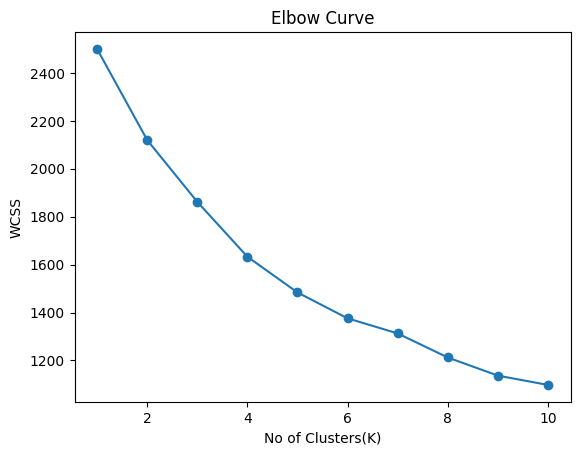

In [20]:
plt.plot(range(1,11),wcss,marker='o')
plt.title("Elbow Curve")
plt.xlabel("No of Clusters(K)")
plt.ylabel("WCSS")

Text(0, 0.5, 'WCSS')

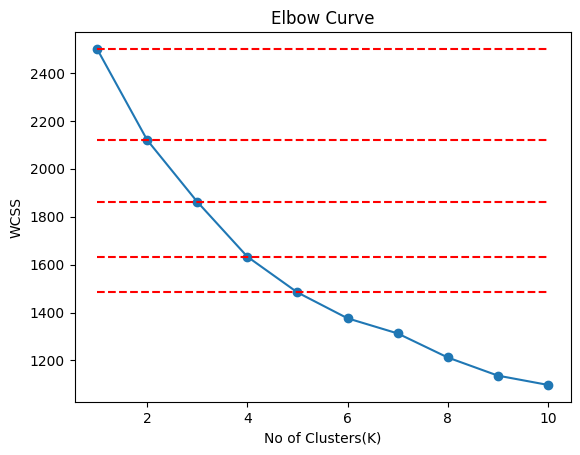

In [21]:
plt.plot(range(1,11),wcss,marker='o')
plt.hlines(wcss[0:5],xmin= 1, xmax = 10,linestyles = "dashed",colors="red")
plt.title("Elbow Curve")
plt.xlabel("No of Clusters(K)")
plt.ylabel("WCSS")

In [22]:
#3 or 4 will be the optimal number of cluster for kmeans